<a href="https://colab.research.google.com/github/minhphu12-oc/gg-colab/blob/sklearn-project-for-machine-learning/project_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

link tải dataset : https://www.kaggle.com/code/buntyshah/insurance-fraud-claims-detection

# BƯỚC 1: ĐỌC DỮ LIỆU

1.1 gọi dữ liệu và đọc 5 dòng đầu

In [232]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,make_scorer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [233]:
df = pd.read_csv('insurance_claims.csv')
df.head(5)

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,Y,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,?,5070,780,780,3510,Mercedes,E400,2007,Y,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,NaN
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,NaN
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,NO,6500,1300,650,4550,Accura,RSX,2009,N,NaN


In [234]:
df.shape

(1000, 40)

trong collison_type ( loại va chạm có những phần có dấu ? thì không phải là thiếu mà là không bị chấn thương nên sẽ chuyển nó về thành None )

phần authorities_contacted có những phần là NaN là bị thiếu nhưng đây là những chỗ cần điền dữ liệu nên chúng ta sẽ cần cách để điền lại vào những chỗ còn thiếu ( câu hỏi yes-no cũng tương tự )

1.2 đọc thông tin dữ liệu

In [235]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   months_as_customer           1000 non-null   int64  
 1   age                          1000 non-null   int64  
 2   policy_number                1000 non-null   int64  
 3   policy_bind_date             1000 non-null   object 
 4   policy_state                 1000 non-null   object 
 5   policy_csl                   1000 non-null   object 
 6   policy_deductable            1000 non-null   int64  
 7   policy_annual_premium        1000 non-null   float64
 8   umbrella_limit               1000 non-null   int64  
 9   insured_zip                  1000 non-null   int64  
 10  insured_sex                  1000 non-null   object 
 11  insured_education_level      1000 non-null   object 
 12  insured_occupation           1000 non-null   object 
 13  insured_hobbies    

1.3 tìm những chỗ dữ liệu thiếu cần phải điền missing value

In [236]:
print(df.isnull().sum())

months_as_customer                0
age                               0
policy_number                     0
policy_bind_date                  0
policy_state                      0
policy_csl                        0
policy_deductable                 0
policy_annual_premium             0
umbrella_limit                    0
insured_zip                       0
insured_sex                       0
insured_education_level           0
insured_occupation                0
insured_hobbies                   0
insured_relationship              0
capital-gains                     0
capital-loss                      0
incident_date                     0
incident_type                     0
collision_type                    0
incident_severity                 0
authorities_contacted            91
incident_state                    0
incident_city                     0
incident_location                 0
incident_hour_of_the_day          0
number_of_vehicles_involved       0
property_damage             

# Bước 2: Tiền xử lí dữ liệu

2.1 chuyển đổi data

In [237]:
# đổi collision_type từ ? về thành no collision
df['collision_type'] = df['collision_type'].replace('?', 'No collision')
# đổi các dấu ? còn lại ở phần khác về NaN để dễ kiểm soát và điền
df = df.replace('?', np.nan)
# c39 1000 dữ liệu đều là Nan nên chuyển về 0 cho dễ train
df['_c39'] = df["_c39"].replace(np.nan, 0)

2.2 kiểm tra lại dữ liệu

In [238]:
df.head(5)

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,Y,0.0
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,NaN,5070,780,780,3510,Mercedes,E400,2007,Y,0.0
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,0.0
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,0.0
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,NO,6500,1300,650,4550,Accura,RSX,2009,N,0.0


2.3 xử lí dữ liệu

In [239]:
# xác định vấn đề và x y
x = df.drop(columns=['fraud_reported'])
y = df['fraud_reported']

# 1. Loại bỏ các đặc trưng ngày tháng và vị trí có tính chất định danh quá chi tiết (gây quá nhiều cột)
cols_to_drop = ['policy_bind_date', 'incident_date', 'incident_location', 'policy_number', 'insured_zip']
x = x.drop(columns=cols_to_drop, errors='ignore')
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Phân loại lại đặc trưng numerical và categorical sau khi loại bỏ bớt
numerical_cols = x.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = x.select_dtypes(include=['object']).columns.tolist()

# 2. Xây dựng Pipeline con cho từng loại dữ liệu
num_transformer = Pipeline(steps=[('imputer', KNNImputer(n_neighbors=5))])
cate_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

# Gộp quá trình xử lý lại
preprocessor = ColumnTransformer([("num", num_transformer, numerical_cols),("cate", cate_transformer, categorical_cols)])


# Bước 3 : training model

3.1 train model cơ bản

Model: Random Forest
classification_report:
              precision    recall  f1-score   support

           N       0.78      0.88      0.83       145
           Y       0.51      0.33      0.40        55

    accuracy                           0.73       200
   macro avg       0.65      0.61      0.61       200
weighted avg       0.70      0.73      0.71       200




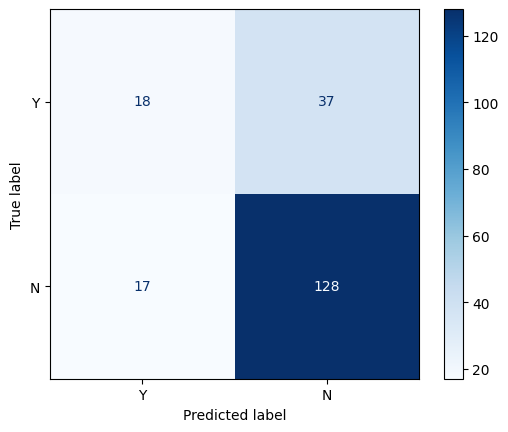

Model: Decision Tree
classification_report:
              precision    recall  f1-score   support

           N       0.84      0.88      0.86       145
           Y       0.62      0.55      0.58        55

    accuracy                           0.79       200
   macro avg       0.73      0.71      0.72       200
weighted avg       0.78      0.79      0.78       200




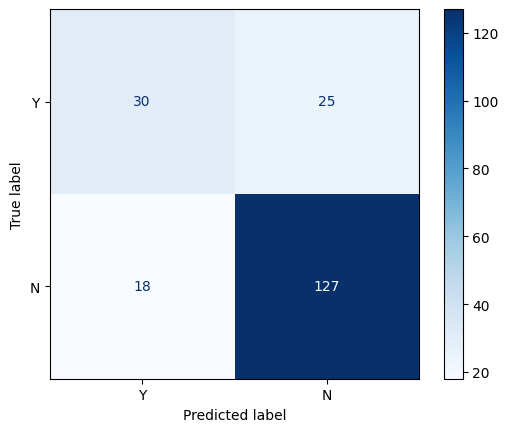

In [240]:
# gọi model
model = {"Random Forest": RandomForestClassifier(random_state=42), "Decision Tree": DecisionTreeClassifier(random_state=42)}
for i in model:
  pipeline = Pipeline([("preprocessor", preprocessor), ("model", model[i])])
  pipeline.fit(x_train, y_train)
  y_pred = pipeline.predict(x_test)

  print(f"Model: {i}")
  print(f"classification_report:")
  print(classification_report(y_test, y_pred))
  print()
  con = confusion_matrix(y_test, y_pred, labels=["Y", "N"])
  disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
  disp.plot(cmap = "Blues")
  plt.show()

decision tree có vẻ đang học tốt hơn rf nhưng mà điểm của cả hai model vẫn quá kém . giờ thử gridsearch xem model có cải tiến hơn không

3.2 tuning

--- RANDOM FOREST ---
Best Params: {'model__bootstrap': True, 'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_split': 13, 'model__n_estimators': 210}

classification_report:
              precision    recall  f1-score   support

           N       0.91      0.82      0.86       145
           Y       0.62      0.78      0.69        55

    accuracy                           0.81       200
   macro avg       0.77      0.80      0.78       200
weighted avg       0.83      0.81      0.82       200


0.6935483870967742


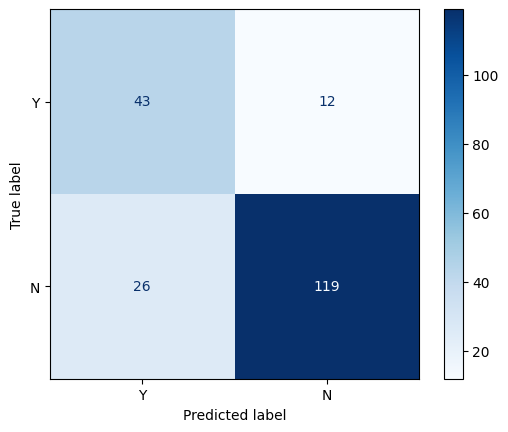


Top 10 Feature Importances:


,Feature,Importance
80,incident_severity_Major Damage,0.195860
51,insured_hobbies_chess,0.083747
81,incident_severity_Minor Damage,0.060317
14,vehicle_claim,0.041582
52,insured_hobbies_cross-fit,0.041171
82,incident_severity_Total Loss,0.039232
13,property_claim,0.036496
11,total_claim_amount,0.032868
12,injury_claim,0.027377
77,collision_type_No collision,0.021146


In [241]:
from sklearn.metrics import make_scorer

# Định nghĩa scorer với mục tiêu tối ưu F1-score của lớp 'Y'
f1_scorer = make_scorer(f1_score, pos_label='Y')

# RANDOM FOREST
param_grid_rf = {
    "model__criterion" : ["entropy"],
    "model__n_estimators" : [207, 210, 213, 250],
    "model__max_depth" : [5],
    "model__min_samples_split": [13, 15, 17],
    "model__bootstrap" : [True]
}

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_rf = GridSearchCV(
    estimator=Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=42, class_weight="balanced"))
    ]),
    param_grid=param_grid_rf,
    cv=st,
    scoring=f1_scorer,
    n_jobs=-1
)

grid_rf.fit(x_train, y_train)
predict = grid_rf.predict(x_test)

print("--- RANDOM FOREST ---")
print("Best Params:", grid_rf.best_params_)
print("\nclassification_report:")
print(classification_report(y_test, predict))
print()
print(f1_score(y_test, predict, pos_label='Y'))
con = confusion_matrix(y_test, predict, labels=["Y", "N"])
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
disp.plot(cmap="Blues")
plt.show()

cate_encoder = grid_rf.best_estimator_.named_steps['preprocessor'].named_transformers_['cate'].named_steps['onehot']
encoded_cate_cols = cate_encoder.get_feature_names_out(categorical_cols).tolist()
all_features = numerical_cols + encoded_cate_cols

best_rf_model = grid_rf.best_estimator_.named_steps['model']
importances = best_rf_model.feature_importances_

# Hiển thị Top 10 đặc trưng quan trọng nhất
feat_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)
print("\nTop 10 Feature Importances:")
display(feat_imp_df.head(10))

Fitting 5 folds for each of 200 candidates, totalling 1000 fits
classification_report:
              precision    recall  f1-score   support

           N       0.92      0.82      0.87       145
           Y       0.63      0.82      0.71        55

    accuracy                           0.82       200
   macro avg       0.78      0.82      0.79       200
weighted avg       0.84      0.82      0.83       200




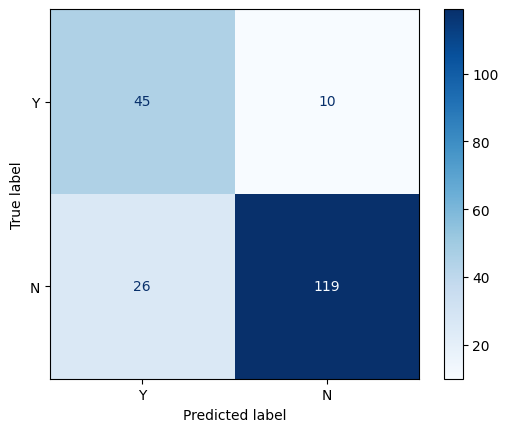

best param: {'model__splitter': 'random', 'model__min_samples_split': 15, 'model__min_samples_leaf': 8, 'model__max_features': None, 'model__max_depth': 4, 'model__criterion': 'log_loss', 'model__ccp_alpha': 0.0001}

Top 10 Feature Importances (Decision Tree):


,Feature,Importance
80,incident_severity_Major Damage,0.470838
51,insured_hobbies_chess,0.226259
52,insured_hobbies_cross-fit,0.202732
22,policy_csl_500/1000,0.037692
28,insured_education_level_JD,0.017082
40,insured_occupation_priv-house-serv,0.013767
104,police_report_available_NO,0.010348
37,insured_occupation_handlers-cleaners,0.008924
81,incident_severity_Minor Damage,0.007078
78,collision_type_Rear Collision,0.005281


In [242]:
# DECISION TREE
param_grid_dt = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__splitter": ["best", "random"],
    "model__max_depth": [3, 4, 5, 6, 7, 8, 10, 12, None],
    "model__min_samples_split": [2, 5, 10, 15, 20, 30, 40],
    "model__min_samples_leaf": [1, 2, 4, 5, 8, 10, 15, 20],
    "model__max_features": [None, "sqrt", "log2"],
    "model__ccp_alpha": [0.0, 0.0001]}

grid_dt = RandomizedSearchCV(estimator=Pipeline([("preprocessor", preprocessor),
                                           ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced"))]),
                                            param_distributions = param_grid_dt, cv = st, n_iter = 200,
                                             scoring = f1_scorer, n_jobs=-1, verbose = 1, refit = True, random_state=42)
grid_dt.fit(x_train, y_train)
predict = grid_dt.predict(x_test)
print(f"classification_report:")
print(classification_report(y_test, predict))
print()
con = confusion_matrix(y_test, predict, labels=["Y", "N"])
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
disp.plot(cmap = "Blues")
plt.show()

best_dt_model = grid_dt.best_estimator_.named_steps['model']
importances_dt = best_dt_model.feature_importances_
print(f"best param: {grid_dt.best_params_}")
# Hiển thị Top 10 đặc trưng quan trọng nhất
feat_imp_dt_df = pd.DataFrame({'Feature': all_features, 'Importance': importances_dt})
feat_imp_dt_df = feat_imp_dt_df.sort_values(by='Importance', ascending=False)
print("\nTop 10 Feature Importances (Decision Tree):")
display(feat_imp_dt_df.head(10))

In [243]:
for name, grid_model in [("Random Forest", grid_rf), ("Decision Tree", grid_dt)]:
    f1 = f1_score(y_test, grid_model.predict(x_test), pos_label='Y')
    prec = precision_score(y_test, grid_model.predict(x_test), pos_label='Y', zero_division=0)
    rec = recall_score(y_test, grid_model.predict(x_test), pos_label='Y')
    print(f"Model: {name}")
    print(f"F1-score (Y): {f1:.4f}")
    print(f"Precision (Y): {prec:.4f}")
    print(f"Recall (Y): {rec:.4f}")

Model: Random Forest
F1-score (Y): 0.6935
Precision (Y): 0.6232
Recall (Y): 0.7818
Model: Decision Tree
F1-score (Y): 0.7143
Precision (Y): 0.6338
Recall (Y): 0.8182


3.3 cải tiến model

ta nhận thấy một vấn đề là recall của model khá ổn sau khi tuning nhưng precision của model lại là cái kéo chỉ số f1 của model xuống rất nhiều. nên ta sẽ thử tăng threehold lên để giúp precision tăng lên xem model có cải thiện được đang kể chỉ số f1 không

In [244]:
# thử tăng threshold lên cho cả hai mô hình đã tuned
thresholds = [0.2, 0.3, 0.4, 0.5, 0.55, 0.60, 0.65, 0.70]

for name, grid_model in [("Random Forest", grid_rf), ("Decision Tree", grid_dt)]:
    print(f"=== THỬ NGHIỆM NGƯỠNG CHO {name.upper()} ===")
    y_idx = list(grid_model.classes_).index('Y')
    y_probs = grid_model.predict_proba(x_test)[:, y_idx]

    for th in thresholds:
        y_pred_th = np.where(y_probs >= th, 'Y', 'N')
        f1 = f1_score(y_test, y_pred_th, pos_label='Y')
        prec = precision_score(y_test, y_pred_th, pos_label='Y', zero_division=0)
        rec = recall_score(y_test, y_pred_th, pos_label='Y')
        print(f"Ngưỡng: {th:.2f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1-score: {f1:.4f}")
    print("\n")

=== THỬ NGHIỆM NGƯỠNG CHO RANDOM FOREST ===
Ngưỡng: 0.20 | Precision: 0.3068 | Recall: 0.9818 | F1-score: 0.4675
Ngưỡng: 0.30 | Precision: 0.3292 | Recall: 0.9636 | F1-score: 0.4907
Ngưỡng: 0.40 | Precision: 0.6000 | Recall: 0.8182 | F1-score: 0.6923
Ngưỡng: 0.50 | Precision: 0.6232 | Recall: 0.7818 | F1-score: 0.6935
Ngưỡng: 0.55 | Precision: 0.5738 | Recall: 0.6364 | F1-score: 0.6034
Ngưỡng: 0.60 | Precision: 0.5660 | Recall: 0.5455 | F1-score: 0.5556
Ngưỡng: 0.65 | Precision: 0.4762 | Recall: 0.1818 | F1-score: 0.2632
Ngưỡng: 0.70 | Precision: 0.5000 | Recall: 0.0182 | F1-score: 0.0351


=== THỬ NGHIỆM NGƯỠNG CHO DECISION TREE ===
Ngưỡng: 0.20 | Precision: 0.6486 | Recall: 0.8727 | F1-score: 0.7442
Ngưỡng: 0.30 | Precision: 0.6486 | Recall: 0.8727 | F1-score: 0.7442
Ngưỡng: 0.40 | Precision: 0.6486 | Recall: 0.8727 | F1-score: 0.7442
Ngưỡng: 0.50 | Precision: 0.6338 | Recall: 0.8182 | F1-score: 0.7143
Ngưỡng: 0.55 | Precision: 0.6667 | Recall: 0.8000 | F1-score: 0.7273
Ngưỡng: 0.60 

0.2 decision tree có tăng nhẹ

qua hai model ta thấy được 2 data quan trọng nhất với model để học là :


*   incident_severity_Major Damage
*   insured_hobbies

ta thử tạo tệp dữ liệu chỉ có 2 dữ liệu đó để xem model học có tốt hơn không



In [245]:
df1 = df[["incident_severity", "insured_hobbies"]].copy()

df1["fraud_reported"] = df["fraud_reported"]

display(df1.head(5))

,incident_severity,insured_hobbies,fraud_reported
0,Major Damage,sleeping,Y
1,Minor Damage,reading,Y
2,Minor Damage,board-games,N
3,Major Damage,board-games,Y
4,Minor Damage,board-games,N


Model: Random Forest
classification_report:
              precision    recall  f1-score   support

           N       0.94      0.82      0.88       145
           Y       0.64      0.85      0.73        55

    accuracy                           0.83       200
   macro avg       0.79      0.84      0.80       200
weighted avg       0.86      0.83      0.84       200




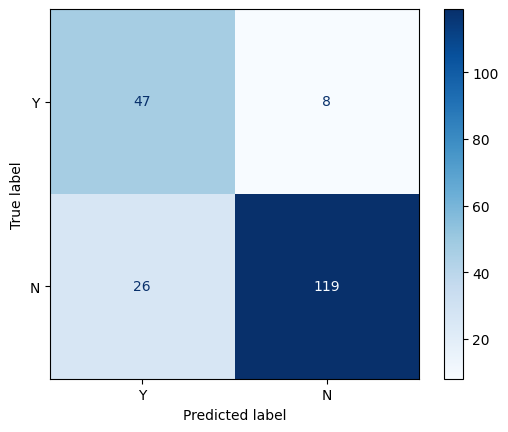




Model: Decision Tree
classification_report:
              precision    recall  f1-score   support

           N       0.94      0.82      0.88       145
           Y       0.65      0.87      0.74        55

    accuracy                           0.83       200
   macro avg       0.80      0.85      0.81       200
weighted avg       0.86      0.83      0.84       200




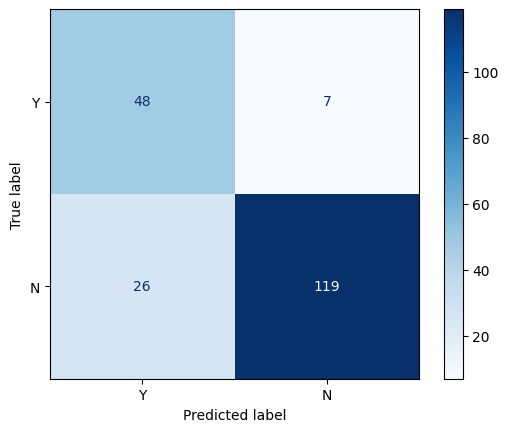

In [246]:
x = df1.drop(columns=['fraud_reported'])
y = df1['fraud_reported']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

categorical_cols_df1 = ['incident_severity', 'insured_hobbies']
pate_transformer_df1 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor_df1 = ColumnTransformer([
    ("cate", pate_transformer_df1, categorical_cols_df1)
])

for name, grid_model in [("Random Forest", grid_rf), ("Decision Tree", grid_dt)]:
    pipeline = Pipeline([
        ("preprocessor", preprocessor_df1),
        ("model", grid_model.best_estimator_.named_steps['model'])
    ])
    pipeline.fit(x_train, y_train)
    y_pred = pipeline.predict(x_test)

    print(f"Model: {name}")
    print(f"classification_report:")
    print(classification_report(y_test, y_pred))
    print()
    con = confusion_matrix(y_test, y_pred, labels=["Y", "N"])
    disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
    disp.plot(cmap = "Blues")
    plt.show()
    print()
    print()
    print()

In [247]:
data = [
    {
        "Model": "Random Forest",
        "Metric": "Precision (Y)",
        "Old": 0.62,
        "New": 0.64
    },
    {
        "Model": "Random Forest",
        "Metric": "Recall (Y)",
        "Old": 0.78,
        "New": 0.85
    },
    {
        "Model": "Random Forest",
        "Metric": "F1-score (Y)",
        "Old": 0.69,
        "New": 0.73
    },
    {
        "Model": "Decision Tree",
        "Metric": "Precision (Y)",
        "Old": 0.65,
        "New": 0.64
    },
    {
        "Model": "Decision Tree",
        "Metric": "Recall (Y)",
        "Old": 0.80,
        "New": 0.85
    },
    {
        "Model": "Decision Tree",
        "Metric": "F1-score (Y)",
        "Old": 0.72,
        "New": 0.73
    }
]

# Tạo DataFrame
compare_df = pd.DataFrame(data)
compare_df["Chênh lệch"] = compare_df["New"] - compare_df["Old"]
def highlight_diff(val):
    if val > 0:
        return 'color: green; font-weight: bold;'
    elif val < 0:
        return 'color: red; font-weight: bold;'
    else:
        return 'color: gray;'
styled_table = compare_df.style.format({
    'Old': '{:.2f}',
    'New': '{:.2f}',
    'Chênh lệch': '{:+.2f}'
    }).map(highlight_diff, subset=['Chênh lệch'])
# Hiển thị bảng so sánh
display(styled_table)

,Model,Metric,Old,New,Chênh lệch
0,Random Forest,Precision (Y),0.62,0.64,+0.02
1,Random Forest,Recall (Y),0.78,0.85,+0.07
2,Random Forest,F1-score (Y),0.69,0.73,+0.04
3,Decision Tree,Precision (Y),0.65,0.64,-0.01
4,Decision Tree,Recall (Y),0.80,0.85,+0.05
5,Decision Tree,F1-score (Y),0.72,0.73,+0.01


ta có thể thấy được model cải tiến rất đáng kể khi trước học 40 feature mà độ dự đoán còn kém hơn việc học 2 feature quan trọng nhất nhưng tăng khả năng dự đoán

giờ ta thử thêm một cột feature xem model có cải tiến nữa không ?

In [248]:
df2 = df[["incident_severity", "insured_hobbies","vehicle_claim"]].copy()

df2["fraud_reported"] = df["fraud_reported"]

display(df2.head(5))

,incident_severity,insured_hobbies,vehicle_claim,fraud_reported
0,Major Damage,sleeping,52080,Y
1,Minor Damage,reading,3510,Y
2,Minor Damage,board-games,23100,N
3,Major Damage,board-games,50720,Y
4,Minor Damage,board-games,4550,N


Model: Random Forest
classification_report:
              precision    recall  f1-score   support

           N       0.94      0.82      0.88       145
           Y       0.64      0.85      0.73        55

    accuracy                           0.83       200
   macro avg       0.79      0.84      0.80       200
weighted avg       0.86      0.83      0.84       200




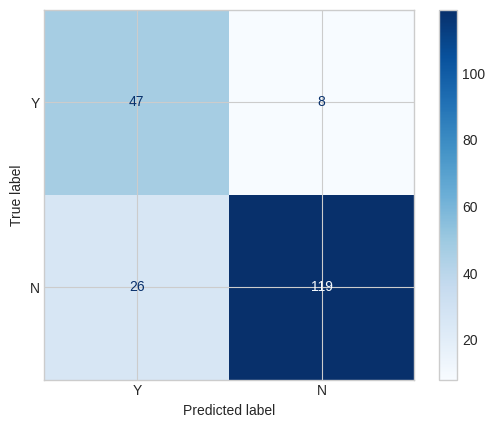




F1-score (Y): 0.7344
Model: Decision Tree
classification_report:
              precision    recall  f1-score   support

           N       0.94      0.82      0.88       145
           Y       0.65      0.87      0.74        55

    accuracy                           0.83       200
   macro avg       0.80      0.85      0.81       200
weighted avg       0.86      0.83      0.84       200




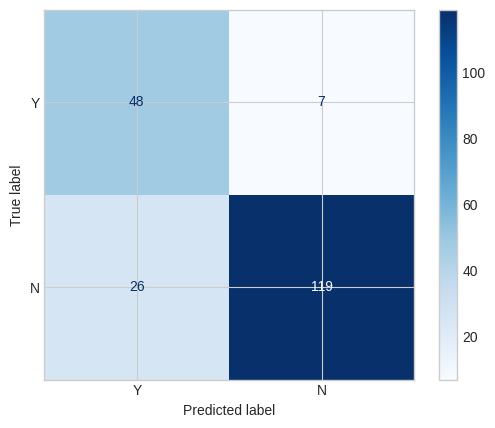




F1-score (Y): 0.7442


In [266]:
x = df2.drop(columns=['fraud_reported'])
y = df2['fraud_reported']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

categorical_cols_df2 = ['incident_severity', 'insured_hobbies','vehicle_claim']
pate_transformer_df2 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor_df2 = ColumnTransformer([
    ("cate", pate_transformer_df2, categorical_cols_df2)
])

for name, grid_model in [("Random Forest", grid_rf), ("Decision Tree", grid_dt)]:
    pipeline = Pipeline([
        ("preprocessor", preprocessor_df1),
        ("model", grid_model.best_estimator_.named_steps['model'])
    ])
    pipeline.fit(x_train, y_train)
    y_pred = pipeline.predict(x_test)

    print(f"Model: {name}")
    print(f"classification_report:")
    print(classification_report(y_test, y_pred))
    print()
    con = confusion_matrix(y_test, y_pred, labels=["Y", "N"])
    disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
    disp.plot(cmap = "Blues")
    plt.show()
    print()
    print()
    print()
    f1 = f1_score(y_test, y_pred, pos_label='Y')
    print(f"F1-score (Y): {f1:.4f}")


In [250]:
data_compare = [
    {
        "Model": "Random Forest",
        "Metric": "Precision (Y)",
        "df1 (2 features)": 0.64,
        "df2 (3 features)": 0.64
    },
    {
        "Model": "Random Forest",
        "Metric": "Recall (Y)",
        "df1 (2 features)": 0.85,
        "df2 (3 features)": 0.85
    },
    {
        "Model": "Random Forest",
        "Metric": "F1-score (Y)",
        "df1 (2 features)": 0.73,
        "df2 (3 features)": 0.73
    },
    {
        "Model": "Decision Tree",
        "Metric": "Precision (Y)",
        "df1 (2 features)": 0.64,
        "df2 (3 features)": 0.67
    },
    {
        "Model": "Decision Tree",
        "Metric": "Recall (Y)",
        "df1 (2 features)": 0.85,
        "df2 (3 features)": 0.85
    },
    {
        "Model": "Decision Tree",
        "Metric": "F1-score (Y)",
        "df1 (2 features)": 0.73,
        "df2 (3 features)": 0.75
    }
]
# Tạo DataFrame
df_compare_models = pd.DataFrame(data_compare)
df_compare_models["Chênh lệch"] = df_compare_models["df2 (3 features)"] - df_compare_models["df1 (2 features)"]
def highlight_diff(val):
    if val > 0:
        return 'color: green; font-weight: bold;'
    elif val < 0:
        return 'color: red; font-weight: bold;'
    else:
        return 'color: gray;'
styled_table_df1_df2 = df_compare_models.style.format({
    'df1 (2 features)': '{:.2f}',
    'df2 (3 features)': '{:.2f}',
    'Chênh lệch': '{:+.2f}'
}).map(highlight_diff, subset=['Chênh lệch'])

display(styled_table_df1_df2)

,Model,Metric,df1 (2 features),df2 (3 features),Chênh lệch
0,Random Forest,Precision (Y),0.64,0.64,+0.00
1,Random Forest,Recall (Y),0.85,0.85,+0.00
2,Random Forest,F1-score (Y),0.73,0.73,+0.00
3,Decision Tree,Precision (Y),0.64,0.67,+0.03
4,Decision Tree,Recall (Y),0.85,0.85,+0.00
5,Decision Tree,F1-score (Y),0.73,0.75,+0.02


# Bước 4: Visualize cây quyết định

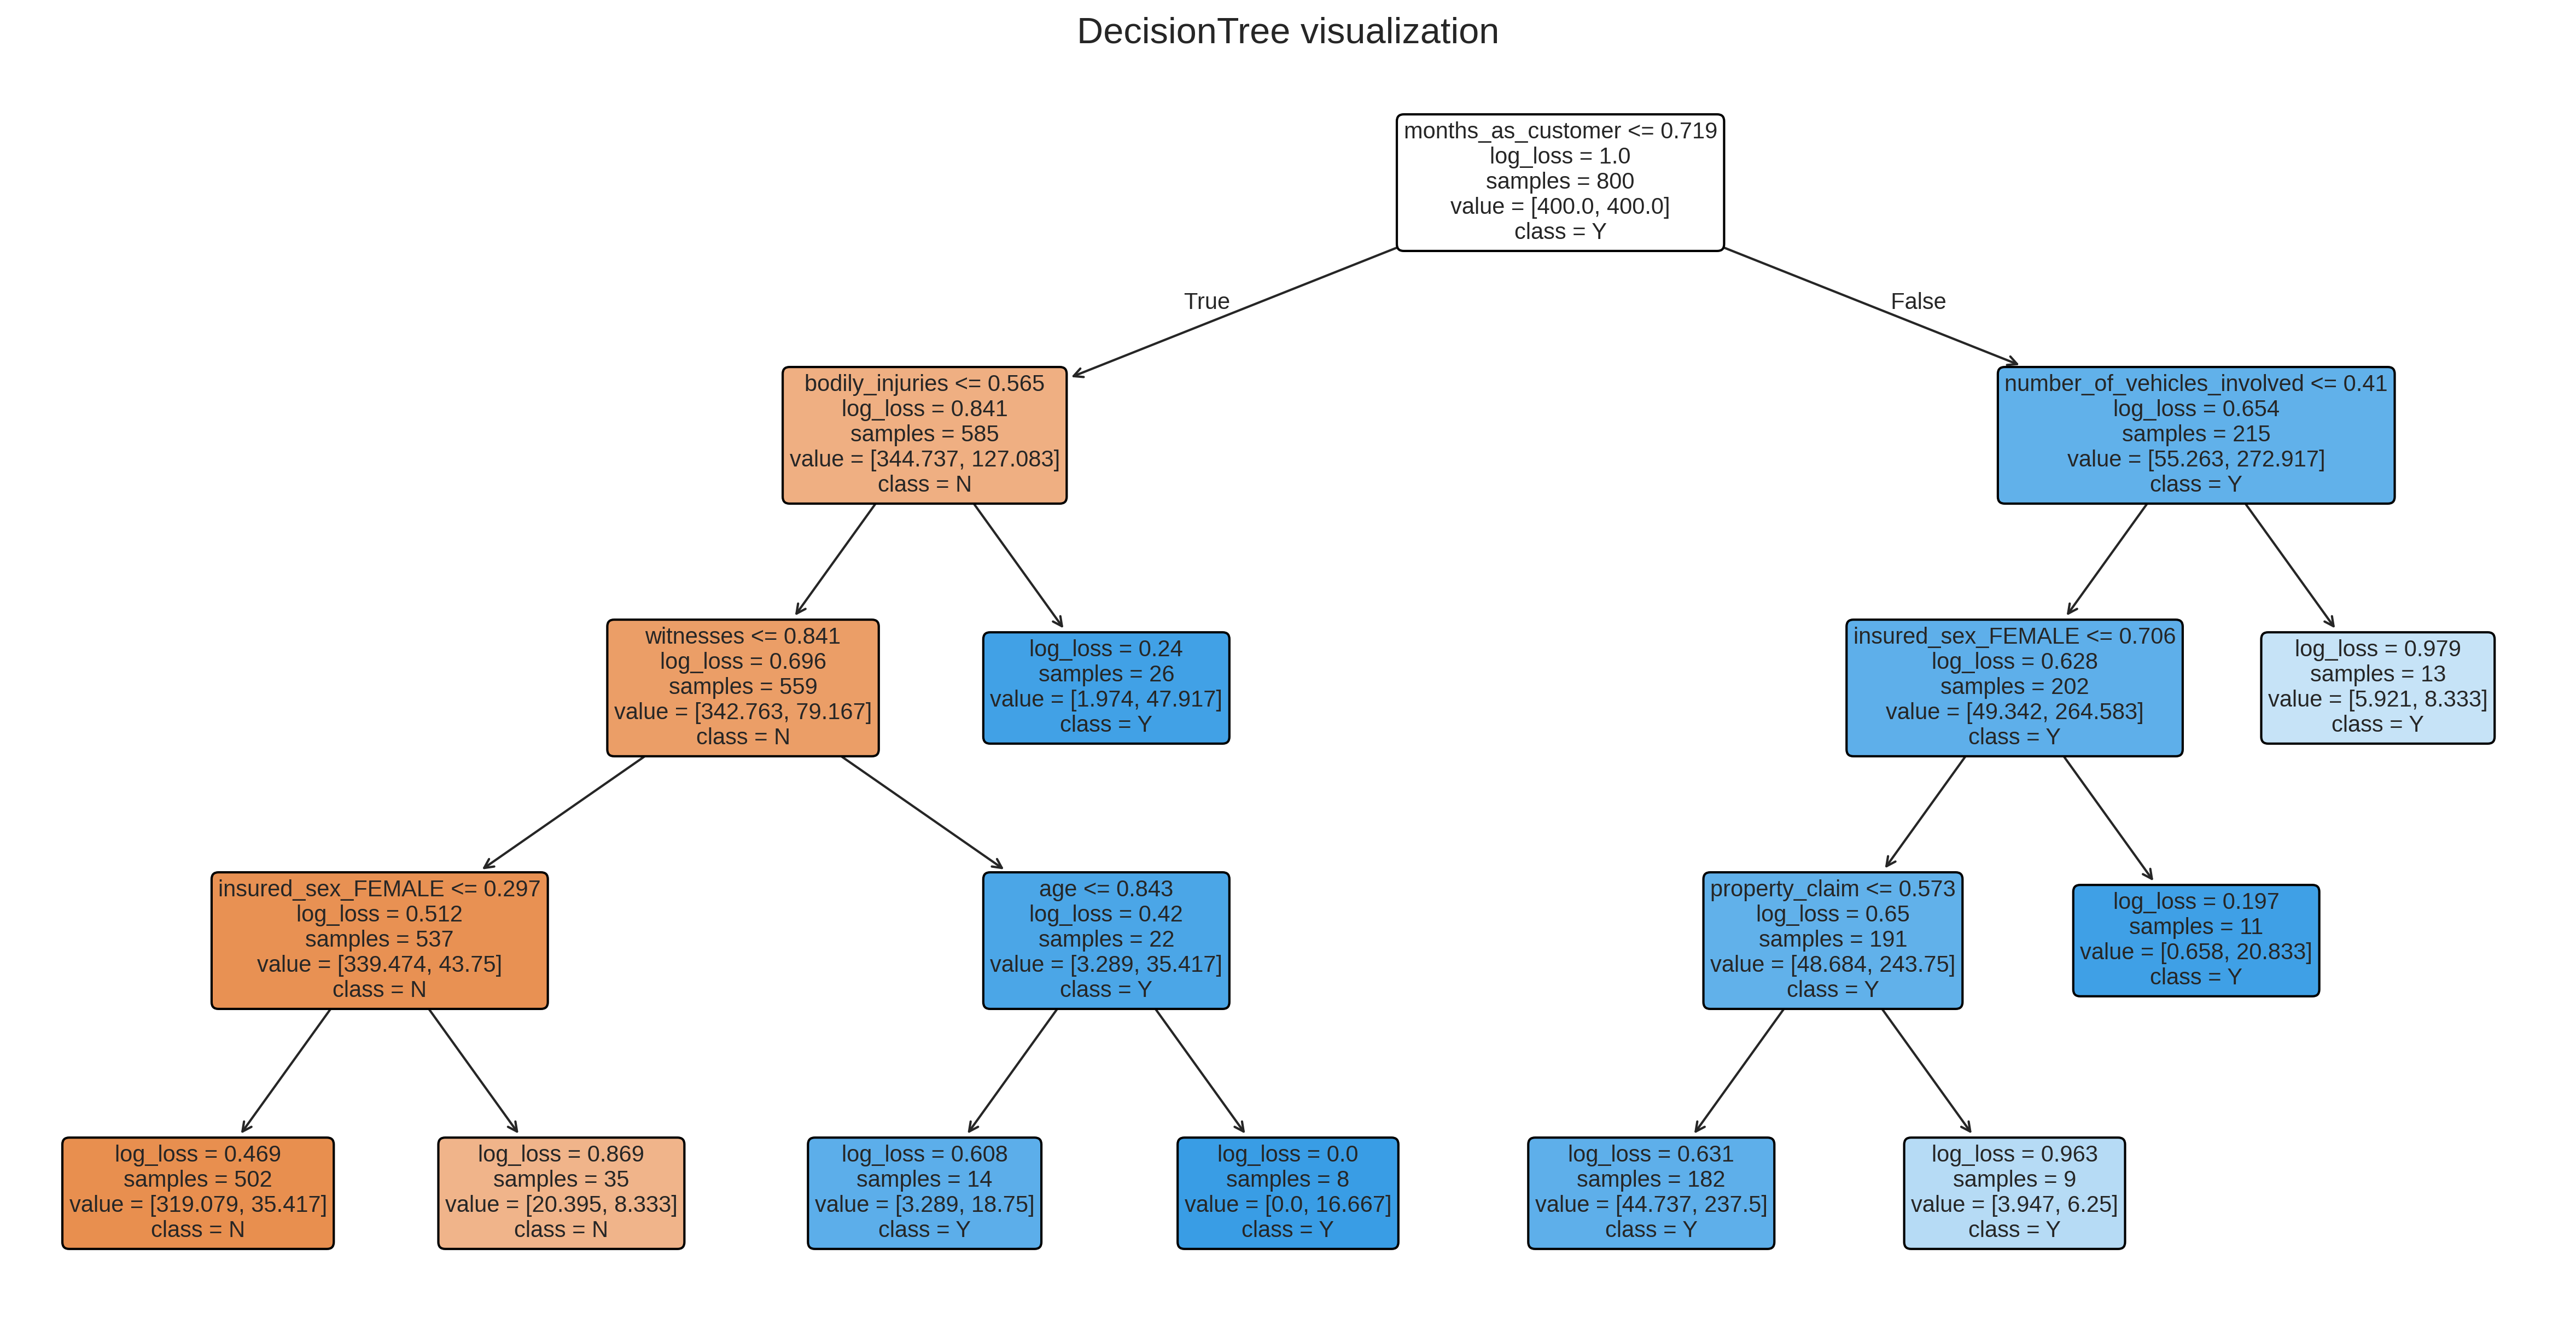

In [261]:
from sklearn.tree import plot_tree

# Lấy mô hình Decision Tree đã được fit tốt nhất từ Grid Search
best_dt = grid_dt.best_estimator_.named_steps['model']

# Lấy danh sách tên các đặc trưng sau khi qua bộ tiền xử lý One-Hot Encoder
feature_names = all_features

# Vẽ cây quyết định
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
plot_tree(
    best_dt,
    max_depth=5,
    feature_names=feature_names,
    class_names=['N', 'Y'],
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax,
)
plt.title("DecisionTree visualization", fontsize=16)
plt.show()

# kết luận:
như vậy sau khi tinh chỉnh dữ liệu, chọn lọc feature quan trọng và điều chỉnh các thông số của cây, ta đã thiết lập được model đơn giản nhất và hiệu quả nhất chỉ với 2-3 feature quan trọng!!!